In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()

while not (ROOT / "configs/base.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("找不到项目根目录")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.utils import load_config, load_labels, get_device
from src.experiments import selected_run

# 获取 E3 选出的最佳模型
E3_RUN = selected_run(ROOT, "E3")
E3_CONFIG = load_config(E3_RUN / "config.yaml")

DEVICE = get_device(E3_CONFIG.get("device", "auto"))
CLASS_NAMES = [c["label"] for c in load_labels(ROOT)]

assert len(CLASS_NAMES) == 8
assert E3_CONFIG["model"]["name"] == "efficientnet_b0"
assert E3_CONFIG["model"]["finetuning"] == "full"
assert E3_CONFIG["augmentation"] == "combined"

print("项目路径：", ROOT)
print("基线模型：", E3_RUN.name)
print("模型结构：", E3_CONFIG["model"]["name"])
print("微调策略：", E3_CONFIG["model"]["finetuning"])
print("数据增强：", E3_CONFIG["augmentation"])
print("运行设备：", DEVICE)
print("类别数量：", len(CLASS_NAMES))

项目路径： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
基线模型： e3_efficientnet_b0_full_combined_s42_20261021T065510_c05233
模型结构： efficientnet_b0
微调策略： full
数据增强： combined
运行设备： mps
类别数量： 8


In [2]:
import torch
import pandas as pd

from PIL import Image, ImageEnhance
from torchvision import transforms as T
from sklearn.metrics import f1_score, accuracy_score

from src.data import (
    build_transforms,
    make_loader,
    dataset_fingerprint
)
from src.evaluate import load_trained_model

# 读取与 E3 相同的输入参数
data_cfg = E3_CONFIG["data"]

tf_args = {
    key: data_cfg[key]
    for key in ("image_size", "mean", "std")
    if key in data_cfg
}

size = data_cfg["image_size"]

clean_transform = build_transforms(
    "none", **tf_args
)

# 模拟主体占比变小
def shrink_subject(image):
    image = image.convert("RGB")
    w, h = image.size

    scale = 0.75
    nw = round(w * scale)
    nh = round(h * scale)

    small = image.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB", (w, h), (128, 128, 128)
    )

    canvas.paste(
        small, ((w - nw) // 2, (h - nh) // 2)
    )

    return canvas

# 固定四种验证条件
stress_transforms = {
    "clean": clean_transform,

    "dim_light": T.Compose([
        T.Lambda(
            lambda img:
            ImageEnhance.Brightness(img).enhance(0.6)
        ),
        clean_transform
    ]),

    "blur": T.Compose([
        T.GaussianBlur(
            kernel_size=5,
            sigma=(1.4, 1.4)
        ),
        clean_transform
    ]),

    "small_subject": T.Compose([
        T.Lambda(shrink_subject),
        clean_transform
    ])
}

# 加载已有 E3 模型
model, checkpoint = load_trained_model(
    E3_RUN,
    device=DEVICE
)

assert checkpoint["dataset_fingerprint"] == dataset_fingerprint(ROOT)
assert checkpoint["class_names"] == CLASS_NAMES

model.eval()

# 在验证集上评价
def evaluate_stress(transform):
    loader = make_loader(
        ROOT / "data/splits/pv_val.csv",
        ROOT,
        transform,
        batch_size=16,
        shuffle=False,
        num_workers=0
    )

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE)
            logits = model(images)

            y_true.extend(labels.tolist())
            y_pred.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=list(range(8)),
            average="macro",
            zero_division=0
        )
    }

results = []

for name, transform in stress_transforms.items():
    metrics = evaluate_stress(transform)

    results.append({
        "condition": name,
        **metrics
    })

    print(
        f"{name}: "
        f"Accuracy={metrics['accuracy']:.4f}, "
        f"Macro-F1={metrics['macro_f1']:.4f}"
    )

baseline_stress = pd.DataFrame(results)

display(baseline_stress)

save_dir = ROOT / "outputs/tables"
save_dir.mkdir(parents=True, exist_ok=True)

baseline_stress.to_csv(
    save_dir / "e4_baseline_stress.csv",
    index=False
)

print("\nE4 基线评价完成")

clean: Accuracy=0.9960, Macro-F1=0.9949
dim_light: Accuracy=0.9894, Macro-F1=0.9875
blur: Accuracy=0.9174, Macro-F1=0.9217
small_subject: Accuracy=0.9784, Macro-F1=0.9765


,condition,accuracy,macro_f1
0,clean,0.996025,0.994868
1,dim_light,0.989399,0.987466
2,blur,0.917403,0.921700
3,small_subject,0.978357,0.976453



E4 基线评价完成


In [3]:
import random
from PIL import Image
from torchvision import transforms as T
from src.data import build_transforms as original_build_transforms

# 随机缩小主体，模拟拍摄距离变化
def random_small_subject(image):
    image = image.convert("RGB")
    w, h = image.size

    scale = random.uniform(0.70, 0.95)

    nw = round(w * scale)
    nh = round(h * scale)

    small = image.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB", (w, h), (128, 128, 128)
    )

    canvas.paste(
        small,
        ((w - nw) // 2, (h - nh) // 2)
    )

    return canvas


# E4 专用数据增强
def build_e4_transforms(
    augmentation="none",
    image_size=224,
    mean=None,
    std=None
):
    # 非 E4 情况完全沿用原来的处理
    if augmentation != "field_robust_v1":
        return original_build_transforms(
            augmentation,
            image_size=image_size,
            mean=mean,
            std=std
        )

    # 从原来的 Combined 增强开始
    base = original_build_transforms(
        "combined",
        image_size=image_size,
        mean=mean,
        std=std
    )

    steps = list(base.transforms)

    # 在 ToTensor 和 Normalize 之前增加增强操作
    extra = [
        # 35% 概率进行轻度模糊
        T.RandomApply([
            T.GaussianBlur(
                kernel_size=5,
                sigma=(0.4, 1.4)
            )
        ], p=0.35),

        # 20% 概率改变主体大小
        T.RandomApply([
            T.Lambda(random_small_subject)
        ], p=0.20),

        # 15% 概率增加较明显的光照变化
        T.RandomApply([
            T.ColorJitter(
                brightness=(0.6, 0.9),
                contrast=(0.7, 1.0)
            )
        ], p=0.15)
    ]

    steps[-2:-2] = extra

    return T.Compose(steps)


E4_TRANSFORM = build_e4_transforms(
    "field_robust_v1",
    **tf_args
)

print("E4 数据增强创建成功")
print(E4_TRANSFORM)

E4 数据增强创建成功
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    RandomApply(
    p=0.35
    GaussianBlur(kernel_size=(5, 5), sigma=(0.4, 1.4))
)
    RandomApply(
    p=0.2
    Lambda()
)
    RandomApply(
    p=0.15
    ColorJitter(brightness=(0.6, 0.9), contrast=(0.7, 1.0), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


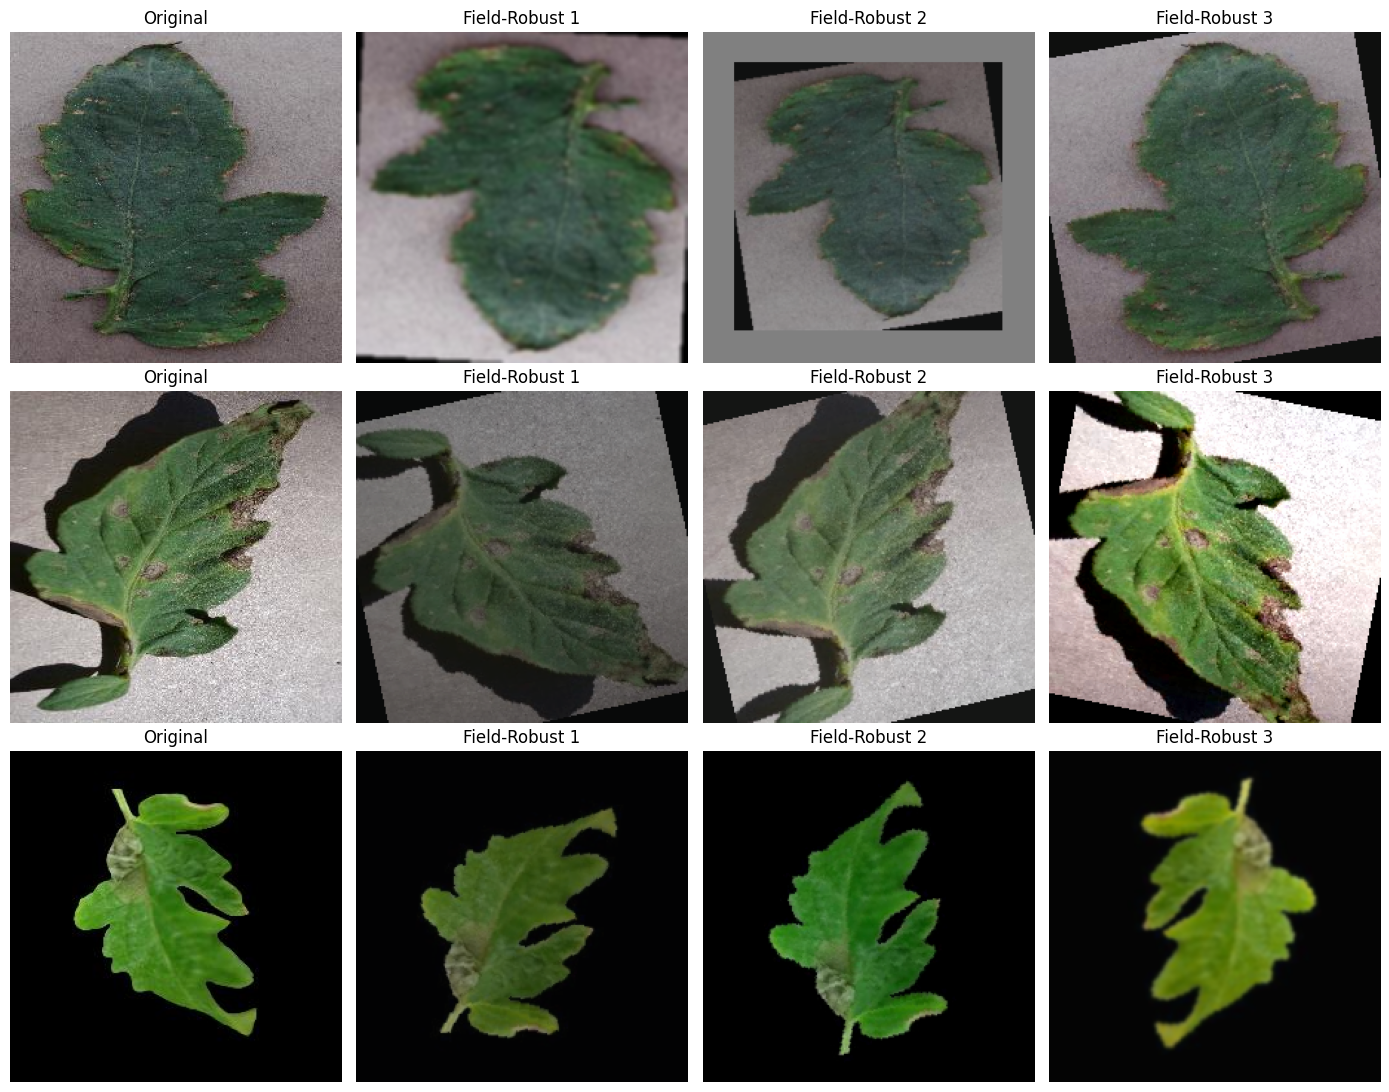

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

train_df = pd.read_csv(
    ROOT / "data/splits/pv_train.csv"
)

samples = (
    train_df.groupby("label_index")
    .sample(n=1, random_state=42)
    .head(3)
)

mean = np.array(
    data_cfg["mean"]
).reshape(3, 1, 1)

std = np.array(
    data_cfg["std"]
).reshape(3, 1, 1)


def restore_image(tensor):
    array = tensor.numpy()
    return np.clip(
        (array * std + mean).transpose(1, 2, 0),
        0, 1
    )


fig, axes = plt.subplots(
    3, 4, figsize=(14, 11)
)

for i, (_, row) in enumerate(samples.iterrows()):

    with Image.open(ROOT / row["image_path"]) as f:
        original = f.convert("RGB").copy()

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")

    for j in range(1, 4):
        augmented = E4_TRANSFORM(original)

        axes[i, j].imshow(
            restore_image(augmented)
        )

        axes[i, j].set_title(
            f"Field-Robust {j}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [8]:
from copy import deepcopy
from datetime import datetime, timezone
from uuid import uuid4

import pandas as pd
import src.train as train_module
from src.utils import load_config

# 复制 E4 配置，不影响原 E3 模型
formal_config = deepcopy(E3_CONFIG)

formal_config["experiment_stage"] = "E4"
formal_config["augmentation"] = "field_robust_v1"
formal_config["parent_run_id"] = E3_RUN.name
formal_config["smoke_test"] = False
formal_config.pop("smoke_limit", None)

# 正式训练参数
formal_config["training"]["epochs"] = 10
formal_config["training"]["batch_size"] = 16
formal_config["training"]["lr"] = 0.0001
formal_config["training"]["num_workers"] = 0

# 记录增强参数，便于复现
formal_config["augmentation_params"] = {
    "blur_probability": 0.35,
    "blur_sigma": [0.4, 1.4],
    "small_subject_probability": 0.20,
    "small_subject_scale": [0.70, 0.95],
    "lighting_probability": 0.15,
    "base_augmentation": "combined"
}

assert formal_config["model"]["name"] == "efficientnet_b0"
assert formal_config["model"]["finetuning"] == "full"
assert formal_config["seed"] == 42

run_id = (
    "e4_field_robust_v1_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
    + "_"
    + uuid4().hex[:6]
)

print("开始正式训练 E4")
print("实验名称：", run_id)

# 临时接入 E4 的数据增强
original_builder = train_module.build_transforms

try:
    train_module.build_transforms = build_e4_transforms

    E4_RUN = train_module.run_experiment(
        ROOT,
        formal_config,
        run_id=run_id
    )

finally:
    train_module.build_transforms = original_builder

# 查看训练结果
status = load_config(E4_RUN / "status.json")

print("\n训练状态：", status["status"])
print("训练轮数：", status["epochs_completed"])
print("最佳轮次：", status["best_epoch"])
print("最佳验证 Macro-F1：", status["best_score"])
print("训练耗时（秒）：", status["seconds"])
print("结果目录：", E4_RUN)

history = pd.read_csv(E4_RUN / "history.csv")
display(history)

开始正式训练 E4
实验名称： e4_field_robust_v1_20261021T102435_db9cb6
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 1: train_loss=0.4513, val_macro_f1=0.9680
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 2: train_loss=0.1193, val_macro_f1=0.9633
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 3: train_loss=0.0784, val_macro_f1=0.9883
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 4: train_loss=0.0572, val_macro_f1=0.9880
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 5: train_loss=0.0469, val_macro_f1=0.9903
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 6: train_loss=0.0334, val_macro_f1=0.9878
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 7: train_loss=0.0330, val_macro_f1=0.9903
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 8: train_loss=0.0281, val_macro_f1=0.9933
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 9: train_loss=0.0242, val_macro_f1=0.9883
e4_field_robust_v1_20261021T102435_db9cb6 | epoch 10: train_loss=0.0267, val_macro_f1=0.9974

训练状态： completed
训练轮数

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,epoch_seconds,elapsed_seconds
0,1,0.451300,0.868254,0.811447,0.089482,0.972615,0.967982,0.0001,217.724501,218.909056
1,2,0.119339,0.960827,0.948465,0.070185,0.976590,0.963322,0.0001,215.344242,434.342350
2,3,0.078387,0.975339,0.968812,0.029830,0.989841,0.988261,0.0001,213.344768,647.688031
3,4,0.057237,0.983212,0.977365,0.030772,0.988958,0.988016,0.0001,216.376175,864.149440
4,5,0.046891,0.984160,0.979599,0.021980,0.992049,0.990294,0.0001,215.712767,1079.863113
5,6,0.033377,0.988903,0.985967,0.026115,0.991166,0.987758,0.0001,215.887580,1295.836206
6,7,0.033011,0.990705,0.987468,0.023295,0.992933,0.990301,0.0001,216.831289,1512.668755
7,8,0.028060,0.991464,0.989711,0.014868,0.995141,0.993289,0.0001,219.908399,1732.665711
8,9,0.024166,0.992791,0.991165,0.027983,0.992049,0.988271,0.0001,208.175562,1940.929776
9,10,0.026658,0.991558,0.989347,0.013781,0.997792,0.997356,0.0001,201.219640,2142.150202


In [9]:

# E4 与 E3 四种条件下的鲁棒性对比
from pathlib import Path
import pandas as pd
from src.evaluate import load_trained_model

# 指定刚刚训练成功的 E4 实验
E4_RUN = ROOT / "outputs/runs/e4_field_robust_v1_20261021T102435_db9cb6"

assert (E4_RUN / "best.pt").exists(), "找不到 E4 最佳模型权重"

# 加载 E4 最佳模型
e4_model, e4_checkpoint = load_trained_model(
    E4_RUN,
    device=DEVICE
)
e4_model.eval()

# 使用前面完全相同的测试函数和四种条件
# evaluate_stress 内部使用变量 model
e3_model = model

e4_results = []

try:
    model = e4_model

    for condition, transform in stress_transforms.items():
        metrics = evaluate_stress(transform)

        e4_results.append({
            "condition": condition,
            "accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"]
        })

        print(
            f"E4 | {condition}: "
            f"Accuracy={metrics['accuracy']:.4f}, "
            f"Macro-F1={metrics['macro_f1']:.4f}"
        )
finally:
    model = e3_model

# 合并 E3、E4 结果
e4_stress = pd.DataFrame(e4_results)

comparison = baseline_stress.merge(
    e4_stress,
    on="condition",
    suffixes=("_e3", "_e4")
)

comparison["f1_improvement"] = (
    comparison["macro_f1_e4"]
    - comparison["macro_f1_e3"]
)

comparison["accuracy_improvement"] = (
    comparison["accuracy_e4"]
    - comparison["accuracy_e3"]
)

print("\nE3 与 E4 鲁棒性对比：")
display(comparison.round(4))

# 按事先确定的规则判断 E4 是否达到目标
stress_conditions = ["dim_light", "blur", "small_subject"]

e3_stress_mean = comparison.loc[
    comparison["condition"].isin(stress_conditions),
    "macro_f1_e3"
].mean()

e4_stress_mean = comparison.loc[
    comparison["condition"].isin(stress_conditions),
    "macro_f1_e4"
].mean()

e3_clean = comparison.loc[
    comparison["condition"] == "clean",
    "macro_f1_e3"
].iloc[0]

e4_clean = comparison.loc[
    comparison["condition"] == "clean",
    "macro_f1_e4"
].iloc[0]

clean_ok = e4_clean >= e3_clean - 0.01
robust_ok = e4_stress_mean > e3_stress_mean

print("\n=== E4 预设目标检验 ===")
print(f"E3 扰动平均 Macro-F1: {e3_stress_mean:.4f}")
print(f"E4 扰动平均 Macro-F1: {e4_stress_mean:.4f}")
print(f"正常条件性能保持: {'通过' if clean_ok else '未通过'}")
print(f"扰动条件平均改善: {'通过' if robust_ok else '未通过'}")
print(f"总体判定: {'达到预设目标' if clean_ok and robust_ok else '未达到预设目标'}")

# 保存对比结果
save_dir = ROOT / "outputs/tables"
save_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    save_dir / "e4_e3_stress_comparison.csv",
    index=False
)

print("\n结果已保存：", save_dir / "e4_e3_stress_comparison.csv")


E4 | clean: Accuracy=0.9978, Macro-F1=0.9974
E4 | dim_light: Accuracy=0.9951, Macro-F1=0.9934
E4 | blur: Accuracy=0.9929, Macro-F1=0.9912
E4 | small_subject: Accuracy=0.9912, Macro-F1=0.9903

E3 与 E4 鲁棒性对比：


,condition,accuracy_e3,macro_f1_e3,accuracy_e4,macro_f1_e4,f1_improvement,accuracy_improvement
0,clean,0.9960,0.9949,0.9978,0.9974,0.0025,0.0018
1,dim_light,0.9894,0.9875,0.9951,0.9934,0.0060,0.0057
2,blur,0.9174,0.9217,0.9929,0.9912,0.0695,0.0755
3,small_subject,0.9784,0.9765,0.9912,0.9903,0.0138,0.0128



=== E4 预设目标检验 ===
E3 扰动平均 Macro-F1: 0.9619
E4 扰动平均 Macro-F1: 0.9916
正常条件性能保持: 通过
扰动条件平均改善: 通过
总体判定: 达到预设目标

结果已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e4_e3_stress_comparison.csv


In [10]:

# E4 独立测试及真实场景泛化评价
from pathlib import Path
import pandas as pd

from src.evaluate import evaluate_checkpoint
from src.experiments import selected_run
from src.utils import load_config

# 1. 确定 E3 和 E4 模型
E3_RUN = selected_run(ROOT, "E3")
E4_RUN = ROOT / "outputs/runs/e4_field_robust_v1_20261021T102435_db9cb6"

assert (E3_RUN / "best.pt").is_file()
assert (E4_RUN / "best.pt").is_file()

e3_config = load_config(E3_RUN / "config.yaml")
e4_config = load_config(E4_RUN / "config.yaml")
e4_status = load_config(E4_RUN / "status.json")

assert e4_status["status"] == "completed"

# 2. 确保使用相同的测试数据
datasets = {
    "plantvillage_test": "test_manifest",
    "plantdoc_external_all": "external_manifest"
}

for key in datasets.values():
    assert e3_config["data"][key] == e4_config["data"][key]

# 3. E3 已经评价过，直接读取保存的结果
e3_metrics_file = E3_RUN / "metrics.json"
e3_saved = (
    load_config(e3_metrics_file)
    if e3_metrics_file.exists()
    else {}
)

rows = []

for dataset_name, manifest_key in datasets.items():
    manifest = e4_config["data"][manifest_key]

    print(f"\n正在评价：{dataset_name}")

    # E3：优先复用之前的结果
    e3_result = e3_saved.get(dataset_name)

    if e3_result is None:
        e3_result = evaluate_checkpoint(
            ROOT, E3_RUN, manifest, dataset_name
        )

    # E4：使用最佳权重正式评价
    e4_result = evaluate_checkpoint(
        ROOT, E4_RUN, manifest, dataset_name
    )

    assert e3_result["sample_count"] == e4_result["sample_count"]

    rows.append({
        "dataset": dataset_name,
        "samples": e4_result["sample_count"],
        "e3_accuracy": e3_result["accuracy"],
        "e4_accuracy": e4_result["accuracy"],
        "accuracy_change": (
            e4_result["accuracy"] - e3_result["accuracy"]
        ),
        "e3_macro_f1": e3_result["macro_f1"],
        "e4_macro_f1": e4_result["macro_f1"],
        "f1_change": (
            e4_result["macro_f1"] - e3_result["macro_f1"]
        )
    })

# 4. 展示并保存结果
test_comparison = pd.DataFrame(rows)

print("\n===== E3 与 E4 独立测试对比 =====")
display(test_comparison.round(4))

save_path = (
    ROOT / "outputs/tables/e3_e4_test_comparison.csv"
)
save_path.parent.mkdir(parents=True, exist_ok=True)

test_comparison.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n对比表已保存：", save_path)
print("E4 完整指标：", E4_RUN / "metrics.json")
print("E4 逐图预测：", E4_RUN / "predictions.csv")



正在评价：plantvillage_test

正在评价：plantdoc_external_all

===== E3 与 E4 独立测试对比 =====


,dataset,samples,e3_accuracy,e4_accuracy,accuracy_change,e3_macro_f1,e4_macro_f1,f1_change
0,plantvillage_test,2259,0.9925,0.9960,0.0035,0.9862,0.9910,0.0049
1,plantdoc_external_all,629,0.2941,0.2544,-0.0397,0.1738,0.1472,-0.0266



对比表已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e3_e4_test_comparison.csv
E4 完整指标： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e4_field_robust_v1_20261021T102435_db9cb6/metrics.json
E4 逐图预测： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/runs/e4_field_robust_v1_20261021T102435_db9cb6/predictions.csv


===== PlantDoc 八类别对比 =====


,类别编号,类别,样本数,E3_Recall,E4_Recall,Recall变化,E3_F1,E4_F1,F1变化,E3预测数量,E4预测数量
0,0,tomato_bacterial_spot,73,0.0137,0.0137,0.0000,0.0263,0.0263,0.0000,3,3
1,1,tomato_early_blight,76,0.6053,0.7763,0.1711,0.3119,0.2987,-0.0131,219,319
2,2,tomato_late_blight,102,0.6275,0.6078,-0.0196,0.4369,0.4397,0.0029,191,180
3,3,tomato_leaf_mold,73,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,6,2
4,4,tomato_septoria_leaf_spot,117,0.5726,0.2906,-0.2821,0.4281,0.2881,-0.1400,196,119
5,5,tomato_tomato_mosaic_virus,53,0.0000,0.0189,0.0189,0.0000,0.0364,0.0364,0,2
6,6,tomato_tomato_yellow_leaf_curl_virus,72,0.0556,0.0139,-0.0417,0.0988,0.0274,-0.0714,9,1
7,7,tomato_healthy,63,0.0476,0.0317,-0.0159,0.0882,0.0606,-0.0276,5,3



===== 类别变化统计 =====
F1 改善类别数： 2
F1 下降类别数： 4

F1 下降最多的类别：


,类别,样本数,E3_F1,E4_F1,F1变化
4,tomato_septoria_leaf_spot,117,0.4281,0.2881,-0.1400
6,tomato_tomato_yellow_leaf_curl_virus,72,0.0988,0.0274,-0.0714
7,tomato_healthy,63,0.0882,0.0606,-0.0276
1,tomato_early_blight,76,0.3119,0.2987,-0.0131
0,tomato_bacterial_spot,73,0.0263,0.0263,0.0000


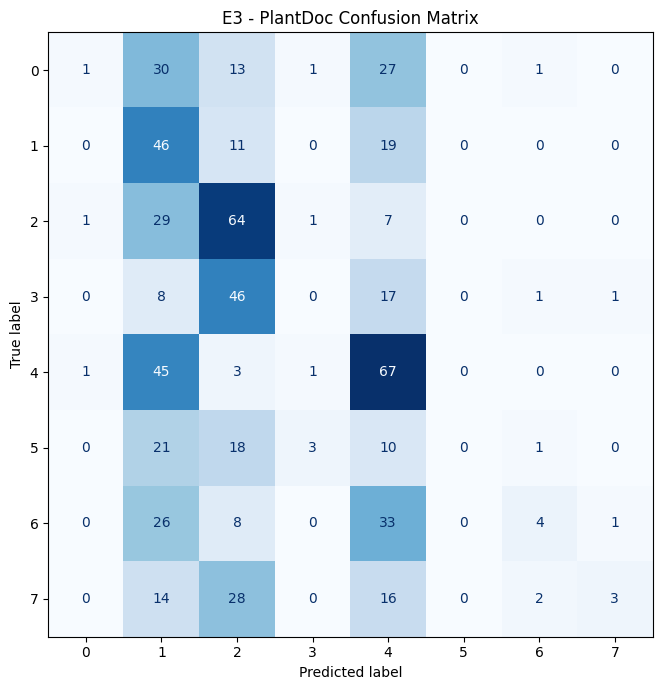

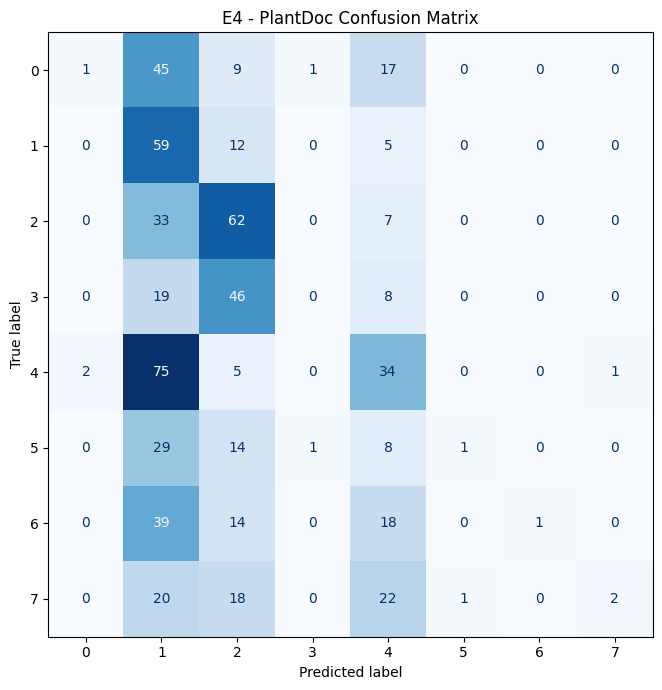


类别编号对应关系：
0: tomato_bacterial_spot
1: tomato_early_blight
2: tomato_late_blight
3: tomato_leaf_mold
4: tomato_septoria_leaf_spot
5: tomato_tomato_mosaic_virus
6: tomato_tomato_yellow_leaf_curl_virus
7: tomato_healthy

结果已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e3_e4_plantdoc_per_class.csv


In [11]:

# E3 / E4：PlantDoc 八类别表现与混淆矩阵
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from src.utils import load_config

# 使用前一个单元格已经定义的 E3_RUN、E4_RUN
dataset_key = "plantdoc_external_all"

e3 = load_config(E3_RUN / "metrics.json")[dataset_key]
e4 = load_config(E4_RUN / "metrics.json")[dataset_key]

classes = e3["class_names"]
assert classes == e4["class_names"]
assert len(classes) == 8

cm_e3 = np.array(e3["confusion_matrix"])
cm_e4 = np.array(e4["confusion_matrix"])

# 1. 逐类别对比
rows = []

for i, name in enumerate(classes):
    r3 = e3["classification_report"][name]
    r4 = e4["classification_report"][name]

    rows.append({
        "类别编号": i,
        "类别": name,
        "样本数": int(r3["support"]),
        "E3_Recall": r3["recall"],
        "E4_Recall": r4["recall"],
        "Recall变化": r4["recall"] - r3["recall"],
        "E3_F1": r3["f1-score"],
        "E4_F1": r4["f1-score"],
        "F1变化": r4["f1-score"] - r3["f1-score"],
        "E3预测数量": int(cm_e3[:, i].sum()),
        "E4预测数量": int(cm_e4[:, i].sum())
    })

class_comparison = pd.DataFrame(rows)

print("===== PlantDoc 八类别对比 =====")
display(class_comparison.round(4))

# 2. 汇总改善与退步的类别
print("\n===== 类别变化统计 =====")
print("F1 改善类别数：", (class_comparison["F1变化"] > 0).sum())
print("F1 下降类别数：", (class_comparison["F1变化"] < 0).sum())

print("\nF1 下降最多的类别：")
display(
    class_comparison.sort_values("F1变化")
    [["类别", "样本数", "E3_F1", "E4_F1", "F1变化"]]
    .head(5).round(4)
)

# 3. 显示 E3、E4 混淆矩阵
# 横轴：预测类别；纵轴：真实类别
for model_name, cm in [("E3", cm_e3), ("E4", cm_e4)]:
    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(8))
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - PlantDoc Confusion Matrix")
    plt.tight_layout()
    plt.show()

# 4. 保存八类别对比表
save_path = ROOT / "outputs/tables/e3_e4_plantdoc_per_class.csv"
save_path.parent.mkdir(parents=True, exist_ok=True)

class_comparison.to_csv(
    save_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n类别编号对应关系：")
for i, name in enumerate(classes):
    print(f"{i}: {name}")

print("\n结果已保存：", save_path)


===== E3 / E4 样本级变化 =====
status
两者都错误        418
两者都正确        134
E3正确_E4错误     51
E3错误_E4正确     26

===== E3 正确但 E4 错误：主要误判方向 =====


,true_label,predicted_label_e4,样本数
5,tomato_septoria_leaf_spot,tomato_early_blight,28
2,tomato_late_blight,tomato_early_blight,5
6,tomato_septoria_leaf_spot,tomato_late_blight,4
0,tomato_early_blight,tomato_late_blight,3
1,tomato_healthy,tomato_septoria_leaf_spot,3
3,tomato_late_blight,tomato_septoria_leaf_spot,3
4,tomato_septoria_leaf_spot,tomato_bacterial_spot,2
7,tomato_tomato_yellow_leaf_curl_virus,tomato_early_blight,1
8,tomato_tomato_yellow_leaf_curl_virus,tomato_late_blight,1
9,tomato_tomato_yellow_leaf_curl_virus,tomato_septoria_leaf_spot,1



===== E3 错误但 E4 正确：主要改善类别 =====


,true_label,改善样本数
0,tomato_early_blight,16
2,tomato_late_blight,6
1,tomato_healthy,2
3,tomato_septoria_leaf_spot,1
4,tomato_tomato_mosaic_virus,1


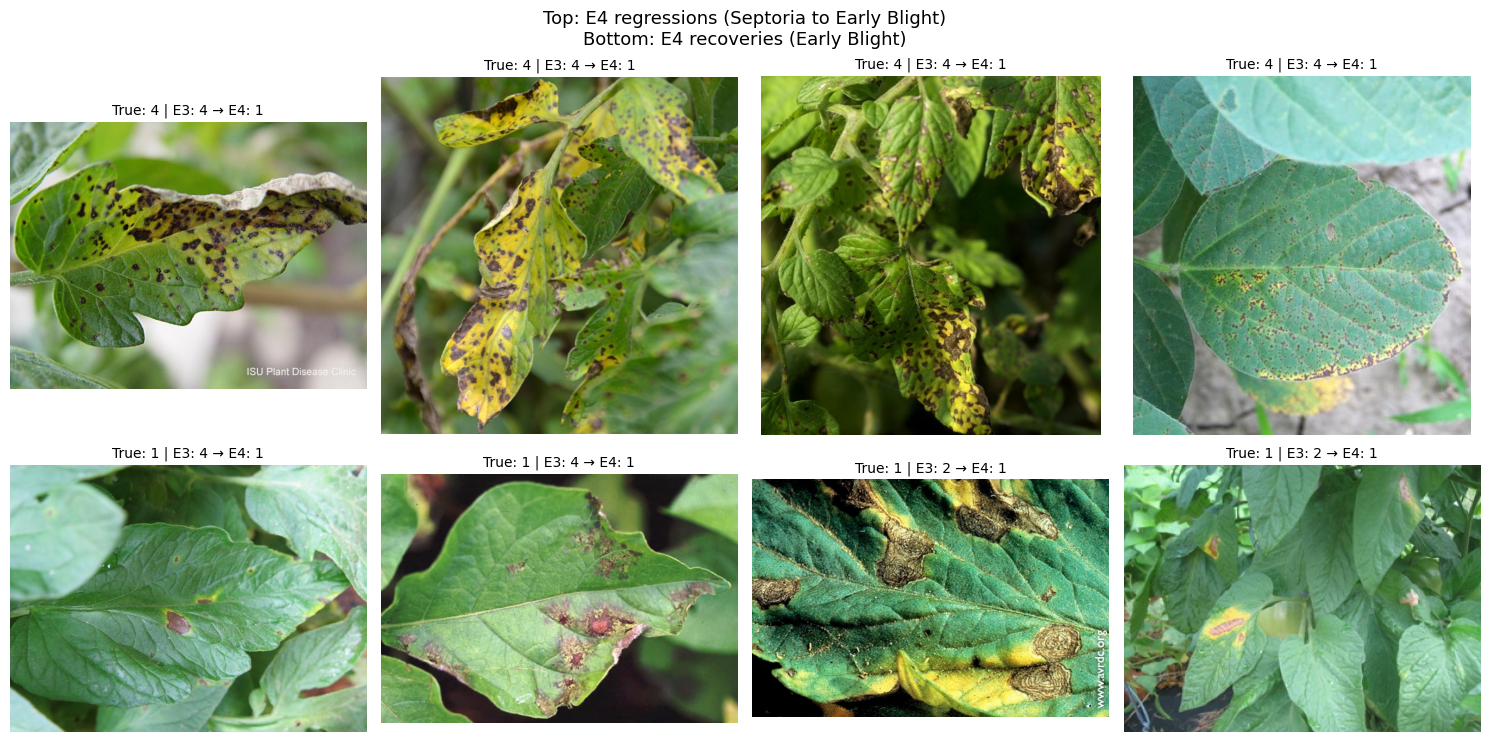


逐图对比已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/tables/e3_e4_plantdoc_sample_changes.csv


In [12]:

# E3 → E4：逐图预测变化与典型样本可视化

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATASET = "plantdoc_external_all"

# 1. 读取已经保存的逐图预测
def read_predictions(run_dir, suffix):
    df = pd.read_csv(run_dir / "predictions.csv")
    df = df[df["dataset"] == DATASET].copy()

    keys = [
        "image_path", "original_split",
        "true_index", "true_label"
    ]
    values = [
        "predicted_index", "predicted_label", "confidence"
    ]

    return df[keys + values].rename(
        columns={name: f"{name}_{suffix}" for name in values}
    )

e3_preds = read_predictions(E3_RUN, "e3")
e4_preds = read_predictions(E4_RUN, "e4")

# 2. 按图片路径与真实标签匹配，避免行顺序错位
paired = e3_preds.merge(
    e4_preds,
    on=["image_path", "original_split", "true_index", "true_label"],
    how="inner",
    validate="one_to_one"
)

assert len(paired) == 629, f"样本匹配异常：{len(paired)}"

paired["e3_correct"] = (
    paired["predicted_index_e3"] == paired["true_index"]
)
paired["e4_correct"] = (
    paired["predicted_index_e4"] == paired["true_index"]
)

paired["status"] = np.select(
    [
        paired["e3_correct"] & paired["e4_correct"],
        paired["e3_correct"] & ~paired["e4_correct"],
        ~paired["e3_correct"] & paired["e4_correct"]
    ],
    [
        "两者都正确",
        "E3正确_E4错误",
        "E3错误_E4正确"
    ],
    default="两者都错误"
)

# 3. 统计同一图片的预测变化
print("===== E3 / E4 样本级变化 =====")
print(paired["status"].value_counts().to_string())

print("\n===== E3 正确但 E4 错误：主要误判方向 =====")
regressed = paired[
    paired["status"] == "E3正确_E4错误"
]

display(
    regressed.groupby(
        ["true_label", "predicted_label_e4"]
    ).size()
    .reset_index(name="样本数")
    .sort_values("样本数", ascending=False)
    .head(10)
)

print("\n===== E3 错误但 E4 正确：主要改善类别 =====")
recovered = paired[
    paired["status"] == "E3错误_E4正确"
]

display(
    recovered.groupby("true_label")
    .size()
    .reset_index(name="改善样本数")
    .sort_values("改善样本数", ascending=False)
)

# 4. 选择典型案例
# 重点：斑枯病被 E4 误判为早疫病
bad_cases = paired[
    (paired["true_index"] == 4) &
    (paired["predicted_index_e3"] == 4) &
    (paired["predicted_index_e4"] == 1)
]

# 对照：早疫病被 E4 纠正的案例
good_cases = paired[
    (paired["true_index"] == 1) &
    (paired["status"] == "E3错误_E4正确")
]

bad_samples = bad_cases.sample(
    n=min(4, len(bad_cases)), random_state=42
)
good_samples = good_cases.sample(
    n=min(4, len(good_cases)), random_state=42
)

# 5. 展示原始图片
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for row_idx, samples in enumerate(
    [bad_samples, good_samples]
):
    for col_idx, (_, item) in enumerate(
        samples.iterrows()
    ):
        ax = axes[row_idx, col_idx]
        path = ROOT / item["image_path"]

        with Image.open(path) as im:
            ax.imshow(im.convert("RGB"))

        ax.set_title(
            f"True: {int(item['true_index'])} | "
            f"E3: {int(item['predicted_index_e3'])} → "
            f"E4: {int(item['predicted_index_e4'])}",
            fontsize=10
        )
        ax.axis("off")

    for col_idx in range(len(samples), 4):
        axes[row_idx, col_idx].axis("off")

fig.suptitle(
    "Top: E4 regressions (Septoria to Early Blight)\n"
    "Bottom: E4 recoveries (Early Blight)",
    fontsize=13
)
plt.tight_layout()
plt.show()

# 6. 保存逐图对比数据
save_path = (
    ROOT / "outputs/tables/e3_e4_plantdoc_sample_changes.csv"
)
save_path.parent.mkdir(parents=True, exist_ok=True)
paired.to_csv(save_path, index=False, encoding="utf-8-sig")

print("\n逐图对比已保存：", save_path)


正在生成 E3 Grad-CAM ...
正在生成 E4 Grad-CAM ...


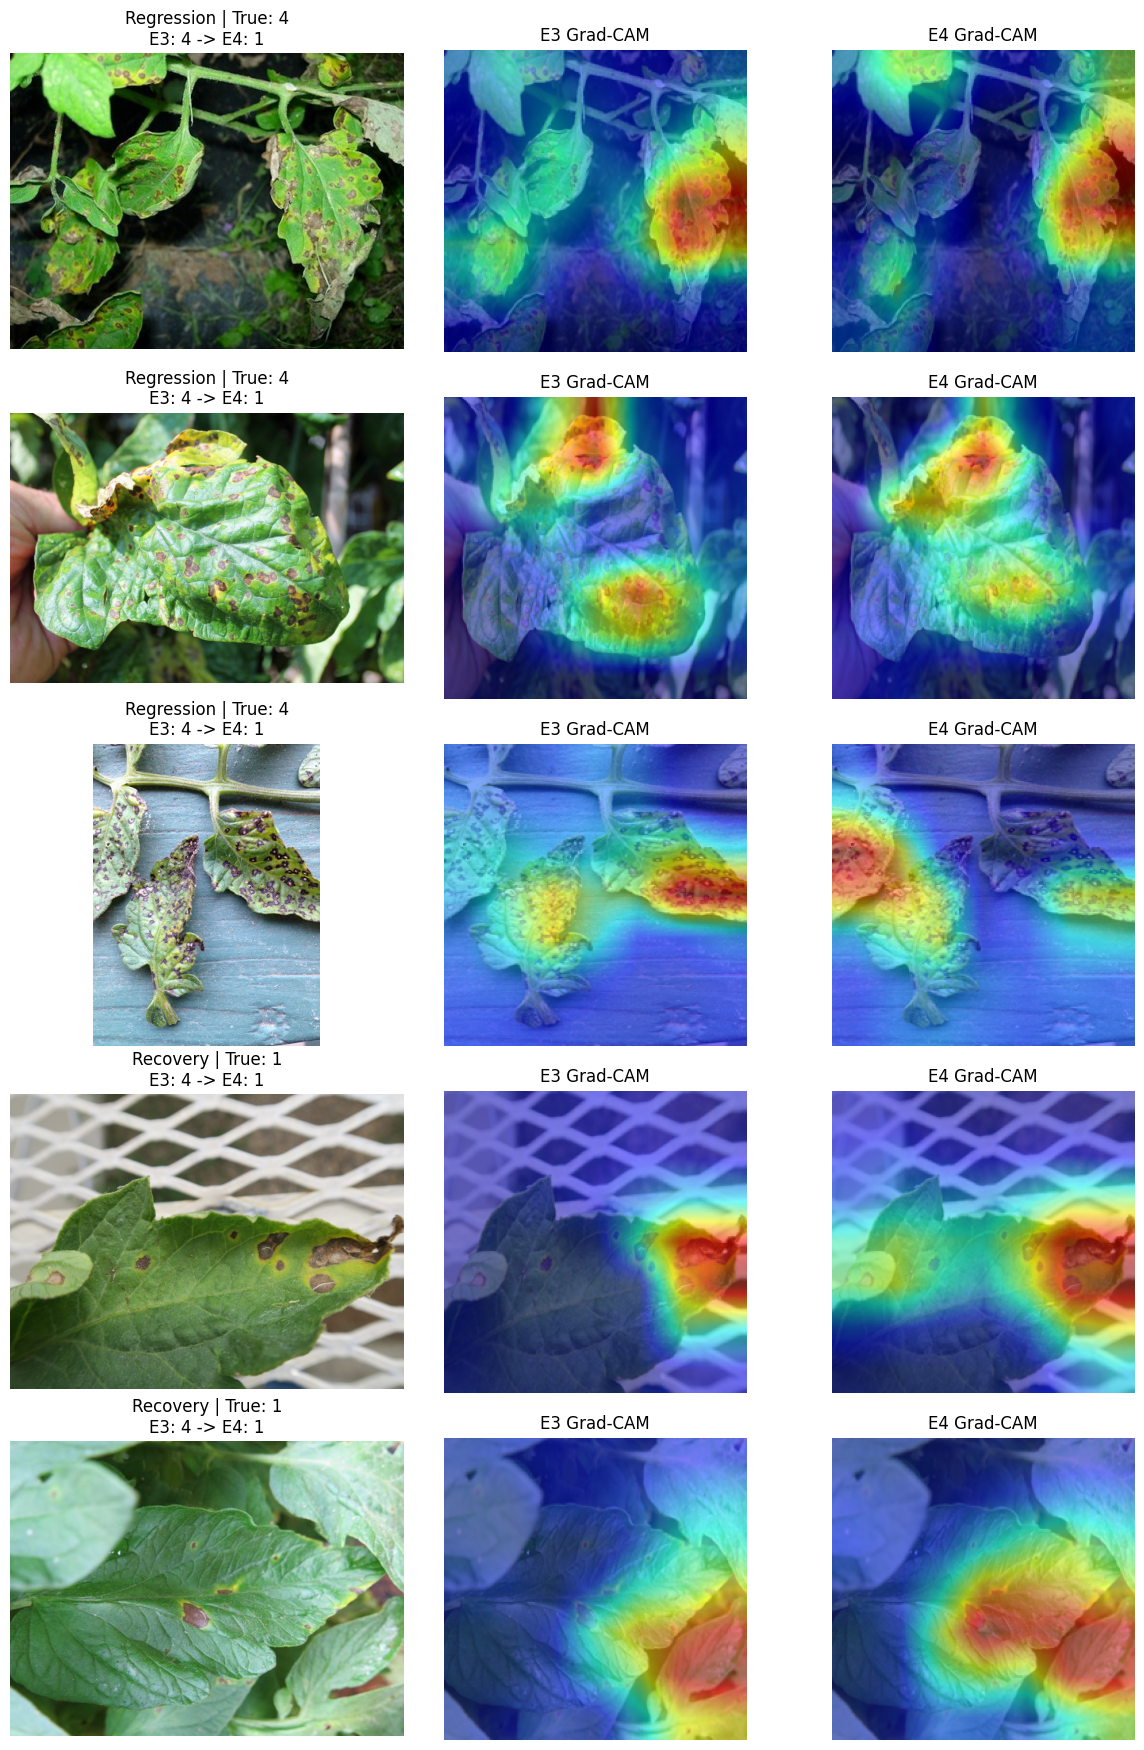

图片已保存： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project/outputs/figures/e3_e4_plantdoc_gradcam_comparison.png


In [13]:

# E3 / E4 Grad-CAM 对照：同图、同类别、同预处理
import gc
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.data import build_transforms
from src.evaluate import load_trained_model
from src.explain import gradcam_image

# 1. 从上一单元格的 paired 中选择案例
regression_cases = paired[
    (paired["true_index"] == 4) &
    (paired["predicted_index_e3"] == 4) &
    (paired["predicted_index_e4"] == 1)
].sort_values("confidence_e4", ascending=False).head(3).copy()

recovery_cases = paired[
    (paired["true_index"] == 1) &
    (paired["predicted_index_e3"] != 1) &
    (paired["predicted_index_e4"] == 1)
].sort_values("confidence_e4", ascending=False).head(2).copy()

regression_cases["case_type"] = "Regression"
recovery_cases["case_type"] = "Recovery"

cases = pd.concat(
    [regression_cases, recovery_cases],
    ignore_index=True
)

assert len(cases) > 0, "没有找到符合条件的案例"

# 2. 分别生成 E3、E4 热力图
overlays = {}

for tag, run_dir in [("E3", E3_RUN), ("E4", E4_RUN)]:
    print(f"正在生成 {tag} Grad-CAM ...")

    cam_model, ckpt = load_trained_model(run_dir, device=DEVICE)
    data_cfg = ckpt["config"]["data"]

    transform = build_transforms(
        "none",
        **{
            key: data_cfg[key]
            for key in ("image_size", "mean", "std")
            if key in data_cfg
        }
    )

    overlays[tag] = []

    for _, case in cases.iterrows():
        with Image.open(ROOT / case["image_path"]) as src:
            image = src.convert("RGB")

        overlay = gradcam_image(
            cam_model,
            ckpt["model_name"],
            image,
            transform,
            target_class=int(case["true_index"]),
            device=DEVICE
        )
        overlays[tag].append(overlay)

    del cam_model
    gc.collect()

# 3. 绘制原图 / E3 / E4 对照
fig, axes = plt.subplots(
    len(cases), 3,
    figsize=(12, 3.5 * len(cases)),
    squeeze=False
)

for i, (_, case) in enumerate(cases.iterrows()):
    with Image.open(ROOT / case["image_path"]) as src:
        original = src.convert("RGB")

    axes[i, 0].imshow(original)
    axes[i, 1].imshow(overlays["E3"][i])
    axes[i, 2].imshow(overlays["E4"][i])

    axes[i, 0].set_title(
        f"{case['case_type']} | True: {int(case['true_index'])}\n"
        f"E3: {int(case['predicted_index_e3'])} "
        f"-> E4: {int(case['predicted_index_e4'])}"
    )
    axes[i, 1].set_title("E3 Grad-CAM")
    axes[i, 2].set_title("E4 Grad-CAM")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

# 4. 保存图片
output_path = (
    ROOT / "outputs/figures/"
    "e3_e4_plantdoc_gradcam_comparison.png"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print("图片已保存：", output_path)


## 结论记录

本实验在 E3 基础上增加随机模糊、光照变化和主体尺度扰动，完成 E4 鲁棒性增强实验，并从模拟扰动、独立测试及真实场景三个方面评价改进效果。

**1. 模拟扰动鲁棒性**

E4 在 PlantVillage 验证集上的最佳 Macro-F1 达到 0.9974。与 E3 相比，弱光、模糊和小主体条件下的 Macro-F1 均有所提升，其中模糊条件由 0.9217 提高至 0.9912。三种扰动条件的平均 Macro-F1 由 0.9619 提高至 0.9916，达到预设的鲁棒性改进目标。

**2. 独立测试与跨场景表现**

在 PlantVillage Test 上，E4 的 Accuracy 由 99.25% 提升至 99.60%，Macro-F1 由 0.9862 提升至 0.9910。但在 PlantDoc 外部数据上，Accuracy 由 29.41% 下降至 25.44%，Macro-F1 由 0.1738 下降至 0.1472。说明模拟扰动条件下的性能改善未能转化为真实场景泛化提升。

**3. 误判变化分析**

在 629 张 PlantDoc 图像中，E3 和 E4 均正确识别 134 张，均错误识别 418 张；E4 新增正确识别 26 张，同时新增错误识别 51 张。其中 28 张新增错误来自斑枯病被误判为早疫病，说明 E4 的类别预测偏向进一步加重。

**4. Grad-CAM 分析**

选取 3 张 E4 新增误判样本及 2 张纠正样本进行 Grad-CAM 对比。结果显示，两种模型在多数案例中均关注叶片病斑及其邻近区域，但仍可能产生不同预测。部分样本存在注意区域变化，提示误判可能与病害特征区分及复杂场景下的特征表达有关，而不能简单归因于背景干扰。Grad-CAM 仅提供定性解释，不能直接证明误判原因。

**5. 最终结论**

E4 有效提高了模型在预设模拟扰动下的鲁棒性，并保持了较高的同域分类性能，但未改善 PlantDoc 真实场景泛化效果。实验表明，模拟数据增强与真实领域迁移之间仍存在差距。本阶段保留 E3 作为真实场景演示的候选基线模型，E4 作为鲁棒性改进对照模型。

由于 PlantDoc 已参与误判诊断，后续若继续设计针对性改进，应使用独立开发数据选择方案，并通过新的外部测试数据进行最终验证。